# Milestone 3: Gán nhãn thủ công (Manual labeling)

**Nhóm:** Nhóm 11 — Nhập môn Khoa học Dữ liệu

---

## 1. Tổng quan và mục tiêu

Giai đoạn gán nhãn thủ công tạo bộ dữ liệu đối chuẩn (ground truth) liên kết các mục tài liệu tham khảo `bibtex` trích xuất từ mã nguồn LaTeX (Milestone 2) với danh sách tài liệu tham khảo có mã arXiv `references` thu thập từ Semantic Scholar API (Milestone 1).

Việc ghép cặp được thực hiện trong phạm vi từng bài báo: mỗi mục BibTeX tương ứng với tối đa một mã `ref_arxiv_id` của cùng bài báo đó, hoặc để trống (`None`) nếu tài liệu tham khảo không nằm trong tập references có mã arXiv. Với nhóm 4 người, tập dữ liệu thủ công cần tối thiểu 20 bài báo (mỗi bài có từ 20 mục BibTeX được gán nhãn trở lên, tổng cộng tối thiểu 400 mục). Từ kết quả gán nhãn, mỗi bài báo có $m$ mục BibTeX và $n$ tài liệu tham khảo arXiv sẽ tạo thành một ma trận nhị phân $m \times n$ phục vụ huấn luyện và đánh giá mô hình.

---

## 2. Tool hỗ trợ gán nhãn và luồng thực hiện

### 2.1. Ý tưởng và luồng xử lý

Trong đồ án, mỗi thành viên trong nhóm 4 người được cấp riêng một khoảng arXiv ID (5000 bài báo/khoảng) để thu thập và xử lý dữ liệu, bao gồm 4 khoảng:
- **Khoảng 1:** `2506.10788` – `2506.15787`
- **Khoảng 2:** `2505.20666` – `2506.00787`
- **Khoảng 3:** `2411.13799` – `2411.18798`
- **Khoảng 4:** `2407.17839` – `2408.01044`

Để tập dữ liệu gán nhãn thủ công đại diện đầy đủ cho cả 4 khoảng dữ liệu được cấp riêng của 4 thành viên, nhóm chọn 5 bài báo từ mỗi khoảng ID (tổng cộng 20 bài báo). Vì việc dò tìm thủ công hoàn toàn bằng mắt giữa hàng nghìn mục BibTeX với danh sách references rất tốn thời gian và dễ sót, nhóm xây dựng module [`src/model/manual_labeling.py`](../src/model/manual_labeling.py) để hỗ trợ quá trình gán nhãn theo 4 bước:

1. **Lọc và gom bài báo (`crawl-team20` / `copy-eligible`):** Quét qua 4 khoảng ID được cấp riêng cho 4 thành viên, mỗi khoảng lấy 5 bài báo (tổng cộng 20 bài) có số lượng mục BibTeX từ 20 đến 250 và có danh sách arXiv references từ Semantic Scholar.
2. **Làm sạch và gợi ý ứng viên (`prepare`):** Gọi các hàm chuẩn hóa từ `src/model/data_cleaning.py` để làm sạch tiêu đề (`clean_title`), tác giả (`clean_authors_list`), năm (`clean_year`) và mã arXiv trích xuất từ text (`extracted_arxiv_id`). Sau đó, công cụ tính điểm tương đồng giữa từng mục BibTeX với các references trong cùng bài báo (dựa trên mã arXiv, độ giống nhau của tiêu đề, họ tác giả và năm) để lấy ra Top-3 ứng viên gần nhất và chia thành 4 nhóm hỗ trợ người duyệt:
   - `AUTO_EXACT_ID`: Mục BibTeX có chứa sẵn mã arXiv trùng khớp với reference.
   - `HIGH_CONF_MATCH`: Tiêu đề và tác giả khớp rõ ràng với độ tương đồng cao.
   - `NEEDS_HUMAN_CHECK`: Các trường hợp nhập nhằng (tiêu đề sửa đổi giữa bản arXiv và bản hội nghị, thiếu trường tác giả, hoặc hai bài khác nhau nhưng có tiêu đề ngắn giống nhau) cần người duyệt kiểm tra kỹ.
   - `LIKELY_NO_ARXIV_REF`: Tài liệu tham khảo không có bản tương ứng trong danh sách arXiv references.
3. **Duyệt nhãn trực quan (`manual_review_ui.html` & `manual_review_sheet.csv`):** Công cụ sinh ra một trang HTML chạy trực tiếp trên trình duyệt, hiển thị song song thông tin BibTeX bên trái và các ứng viên bên phải để người duyệt lọc riêng các ca cần kiểm tra, click chọn đáp án đúng và xuất ra file CSV đã duyệt.
4. **Kiểm tra và xuất dữ liệu (`finalize`):** Đọc file CSV đã duyệt, kiểm tra tính hợp lệ của các mã `groundtruth_arxiv_id` trong phạm vi từng bài báo và xuất ra các file nhãn hoàn chỉnh.

### 2.2. Định dạng dữ liệu đầu ra

Kết quả sau bước `finalize` được lưu thành 2 bảng:
- **Bảng nhãn theo từng mục BibTeX (`manual_labels.csv` / `manual_labels.json`):** Mỗi dòng là một mục BibTeX, gồm các cột `arxiv_id`, `citation_key`, `groundtruth_arxiv_id` (lưu mã `ref_arxiv_id` khớp hoặc `null` nếu không khớp), `is_positive` (`1` hoặc `0`), và `label_source` (`"manual"`).
- **Bảng ma trận ứng viên $m \times n$ (`manual_candidate_pairs.csv`):** Lưu toàn bộ các cặp `(arxiv_id, citation_key, ref_arxiv_id)` của từng bài báo kèm cột `label` (`1` nếu khớp, `0` nếu không khớp).

---

## 3. Minh họa trực tiếp

Đoạn code dưới đây chạy hàm `compute_pair_similarity` trong `src/model/manual_labeling.py` trên một vài cặp dữ liệu thực tế từ tập 20 bài báo để minh họa cách công cụ chấm điểm gợi ý và các tình huống cần con người quyết định (như bài báo đổi tiêu đề khi đăng hội nghị, hoặc hai bài báo khác nhau nhưng trùng tiêu đề ngắn):

In [ ]:
import sys
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "reports" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.model.data_cleaning import clean_bibtex_table, clean_references_table
from src.model.manual_labeling import compute_pair_similarity

sample_bib = clean_bibtex_table(pd.DataFrame([
    {
        "arxiv_id": "2407.17850",
        "citation_key": "rombach2022high",
        "title": "High-resolution image synthesis with latent diffusion models",
        "authors": "Rombach, Robin and Blattmann, Andreas and Lorenz, Dominik",
        "year": 2022,
        "url": "https://arxiv.org/abs/2112.10752",
    },
    {
        "arxiv_id": "2505.20674",
        "citation_key": "hoffmann2022empirical",
        "title": "An empirical analysis of compute-optimal large language model training",
        "authors": "Hoffmann, Jordan and Borgeaud, Sebastian and Mensch, Arthur",
        "year": 2022,
        "url": "",
    },
    {
        "arxiv_id": "2407.17850",
        "citation_key": "gan_2014",
        "title": "Generative Adversarial Networks",
        "authors": "Ian J. Goodfellow and Jean Pouget-Abadie and Mehdi Mirza",
        "year": 2014,
        "url": "",
    },
    {
        "arxiv_id": "2506.10806",
        "citation_key": "zadnik2021foldedII",
        "title": "The folded spin-1/2 XXZ model: II. Thermodynamics and hydrodynamics",
        "authors": "Zadnik, Lenart and Bidzhiev, Kemal and Fagotti, Maurizio",
        "year": 2021,
        "url": "",
    },
]))

sample_ref = clean_references_table(pd.DataFrame([
    {
        "citing_arxiv_id": "2407.17850",
        "ref_arxiv_id": "2112.10752",
        "title": "High-Resolution Image Synthesis with Latent Diffusion Models",
        "authors": ["Robin Rombach", "A. Blattmann", "Dominik Lorenz"],
        "year": 2021,
    },
    {
        "citing_arxiv_id": "2505.20674",
        "ref_arxiv_id": "2203.15556",
        "title": "Training Compute-Optimal Large Language Models",
        "authors": ["Jordan Hoffmann", "Sebastian Borgeaud", "Arthur Mensch"],
        "year": 2022,
    },
    {
        "citing_arxiv_id": "2407.17850",
        "ref_arxiv_id": "2203.00667",
        "title": "Generative Adversarial Networks",
        "authors": ["Gilad Cohen", "R. Giryes"],
        "year": 2021,
    },
    {
        "citing_arxiv_id": "2506.10806",
        "ref_arxiv_id": "2009.04995",
        "title": "The Folded Spin-1/2 XXZ Model: I. Diagonalisation, Jamming, and Ground State Properties",
        "authors": ["Lenart Zadnik", "M. Fagotti"],
        "year": 2020,
    },
]))

final_labels = [
    "2112.10752 (Khớp mã arXiv trực tiếp)",
    "2203.15556 (Khớp: cùng bài Chinchilla, đổi tên ở hội nghị)",
    "None (Không khớp: trùng tiêu đề nhưng khác tác giả và năm)",
    "None (Không khớp: cùng tác giả nhưng là Phần II vs Phần I)",
]

demo_rows = []
for i in range(len(sample_bib)):
    sim = compute_pair_similarity(sample_bib.iloc[i], sample_ref.iloc[i])
    demo_rows.append({
        "arxiv_id": sample_bib.iloc[i]["arxiv_id"],
        "citation_key": sample_bib.iloc[i]["citation_key"],
        "cand_ref_id": sample_ref.iloc[i]["ref_arxiv_id"],
        "exact_id": sim["exact_id_match"],
        "title_score": sim["title_score"],
        "author_score": sim["author_score"],
        "total_score": sim["total_score"],
        "Nhãn sau khi duyệt": final_labels[i],
    })

_display_df = pd.DataFrame(demo_rows)


arxiv_id,citation_key,cand_ref_id,exact_id,title_score,author_score,total_score,Nhãn sau khi duyệt
2407.17850,rombach2022high,2112.10752,True,1.0000,1.0,1.0000,2112.10752 (Khớp mã arXiv trực tiếp)
2505.20674,hoffmann2022empirical,2203.15556,False,0.6792,1.0,0.7690,"2203.15556 (Khớp: cùng bài Chinchilla, đổi tên ở hội nghị)"
2407.17850,gan_2014,2203.00667,False,1.0000,0.0,0.7200,None (Không khớp: trùng tiêu đề nhưng khác tác giả và năm)
2506.10806,zadnik2021foldedII,2009.04995,False,0.5228,1.0,0.6404,None (Không khớp: cùng tác giả nhưng là Phần II vs Phần I)


---

## 4. Kết quả thống kê trên tập dữ liệu gán nhãn thủ công

### 4.1. Thống kê theo từng bài báo

Tập dữ liệu gán nhãn thủ công gồm 20 bài báo (lấy từ 4 khoảng ID được cấp riêng cho 4 thành viên, mỗi khoảng 5 bài) với tổng cộng 1351 mục BibTeX (420 mục khớp với arXiv reference và 931 mục không có bản arXiv tương ứng), tạo ra 44378 cặp trong bảng ma trận ứng viên:

In [2]:
import json
from pathlib import Path
import pandas as pd

stats_file = project_root / "data" / "manual_labeling" / "manual_labeling_stats.json"
if stats_file.is_file():
    stats_data = json.loads(stats_file.read_text(encoding="utf-8"))
else:
    stats_data = json.loads(r'''{
  "total_manual_publications": 20,
  "total_labeled_entries_Q": 1351,
  "total_positive_matches": 420,
  "total_unmatched_entries": 931,
  "overall_match_rate_pct": 31.09,
  "total_candidate_matrix_cells": 44378,
  "manual_publication_ids": [
    "2407.17850",
    "2407.17852",
    "2407.17855",
    "2407.17859",
    "2407.17860",
    "2411.13800",
    "2411.13807",
    "2411.13817",
    "2411.13820",
    "2411.13821",
    "2505.20674",
    "2505.20678",
    "2505.20679",
    "2505.20686",
    "2505.20690",
    "2506.10792",
    "2506.10793",
    "2506.10795",
    "2506.10798",
    "2506.10806"
  ],
  "per_publication": [
    {
      "arxiv_id": "2407.17850",
      "labeled_entries_m": 38,
      "crawled_arxiv_refs_n": 35,
      "candidate_pairs_m_x_n": 1330,
      "positive_matches": 34,
      "unmatched_entries": 4,
      "match_rate_pct": 89.47
    },
    {
      "arxiv_id": "2407.17852",
      "labeled_entries_m": 35,
      "crawled_arxiv_refs_n": 20,
      "candidate_pairs_m_x_n": 700,
      "positive_matches": 15,
      "unmatched_entries": 20,
      "match_rate_pct": 42.86
    },
    {
      "arxiv_id": "2407.17855",
      "labeled_entries_m": 24,
      "crawled_arxiv_refs_n": 12,
      "candidate_pairs_m_x_n": 288,
      "positive_matches": 12,
      "unmatched_entries": 12,
      "match_rate_pct": 50.0
    },
    {
      "arxiv_id": "2407.17859",
      "labeled_entries_m": 72,
      "crawled_arxiv_refs_n": 16,
      "candidate_pairs_m_x_n": 1152,
      "positive_matches": 16,
      "unmatched_entries": 56,
      "match_rate_pct": 22.22
    },
    {
      "arxiv_id": "2407.17860",
      "labeled_entries_m": 48,
      "crawled_arxiv_refs_n": 10,
      "candidate_pairs_m_x_n": 480,
      "positive_matches": 6,
      "unmatched_entries": 42,
      "match_rate_pct": 12.5
    },
    {
      "arxiv_id": "2411.13800",
      "labeled_entries_m": 115,
      "crawled_arxiv_refs_n": 7,
      "candidate_pairs_m_x_n": 805,
      "positive_matches": 7,
      "unmatched_entries": 108,
      "match_rate_pct": 6.09
    },
    {
      "arxiv_id": "2411.13807",
      "labeled_entries_m": 55,
      "crawled_arxiv_refs_n": 44,
      "candidate_pairs_m_x_n": 2420,
      "positive_matches": 45,
      "unmatched_entries": 10,
      "match_rate_pct": 81.82
    },
    {
      "arxiv_id": "2411.13817",
      "labeled_entries_m": 38,
      "crawled_arxiv_refs_n": 10,
      "candidate_pairs_m_x_n": 380,
      "positive_matches": 7,
      "unmatched_entries": 31,
      "match_rate_pct": 18.42
    },
    {
      "arxiv_id": "2411.13820",
      "labeled_entries_m": 45,
      "crawled_arxiv_refs_n": 16,
      "candidate_pairs_m_x_n": 720,
      "positive_matches": 16,
      "unmatched_entries": 29,
      "match_rate_pct": 35.56
    },
    {
      "arxiv_id": "2411.13821",
      "labeled_entries_m": 79,
      "crawled_arxiv_refs_n": 25,
      "candidate_pairs_m_x_n": 1975,
      "positive_matches": 25,
      "unmatched_entries": 54,
      "match_rate_pct": 31.65
    },
    {
      "arxiv_id": "2505.20674",
      "labeled_entries_m": 112,
      "crawled_arxiv_refs_n": 66,
      "candidate_pairs_m_x_n": 7392,
      "positive_matches": 67,
      "unmatched_entries": 45,
      "match_rate_pct": 59.82
    },
    {
      "arxiv_id": "2505.20678",
      "labeled_entries_m": 36,
      "crawled_arxiv_refs_n": 21,
      "candidate_pairs_m_x_n": 756,
      "positive_matches": 21,
      "unmatched_entries": 15,
      "match_rate_pct": 58.33
    },
    {
      "arxiv_id": "2505.20679",
      "labeled_entries_m": 77,
      "crawled_arxiv_refs_n": 5,
      "candidate_pairs_m_x_n": 385,
      "positive_matches": 5,
      "unmatched_entries": 72,
      "match_rate_pct": 6.49
    },
    {
      "arxiv_id": "2505.20686",
      "labeled_entries_m": 249,
      "crawled_arxiv_refs_n": 49,
      "candidate_pairs_m_x_n": 12201,
      "positive_matches": 49,
      "unmatched_entries": 200,
      "match_rate_pct": 19.68
    },
    {
      "arxiv_id": "2505.20690",
      "labeled_entries_m": 26,
      "crawled_arxiv_refs_n": 4,
      "candidate_pairs_m_x_n": 104,
      "positive_matches": 4,
      "unmatched_entries": 22,
      "match_rate_pct": 15.38
    },
    {
      "arxiv_id": "2506.10792",
      "labeled_entries_m": 31,
      "crawled_arxiv_refs_n": 23,
      "candidate_pairs_m_x_n": 713,
      "positive_matches": 1,
      "unmatched_entries": 30,
      "match_rate_pct": 3.23
    },
    {
      "arxiv_id": "2506.10793",
      "labeled_entries_m": 43,
      "crawled_arxiv_refs_n": 11,
      "candidate_pairs_m_x_n": 473,
      "positive_matches": 11,
      "unmatched_entries": 32,
      "match_rate_pct": 25.58
    },
    {
      "arxiv_id": "2506.10795",
      "labeled_entries_m": 31,
      "crawled_arxiv_refs_n": 18,
      "candidate_pairs_m_x_n": 558,
      "positive_matches": 1,
      "unmatched_entries": 30,
      "match_rate_pct": 3.23
    },
    {
      "arxiv_id": "2506.10798",
      "labeled_entries_m": 45,
      "crawled_arxiv_refs_n": 10,
      "candidate_pairs_m_x_n": 450,
      "positive_matches": 6,
      "unmatched_entries": 39,
      "match_rate_pct": 13.33
    },
    {
      "arxiv_id": "2506.10806",
      "labeled_entries_m": 152,
      "crawled_arxiv_refs_n": 73,
      "candidate_pairs_m_x_n": 11096,
      "positive_matches": 72,
      "unmatched_entries": 80,
      "match_rate_pct": 47.37
    }
  ]
}''')

def get_range_label(arxiv_id: str) -> str:
    if arxiv_id.startswith("2506."):
        return "Khoảng 1 (2506.10788–15787)"
    if arxiv_id.startswith("2505."):
        return "Khoảng 2 (2505.20666–2506.00787)"
    if arxiv_id.startswith("2411."):
        return "Khoảng 3 (2411.13799–18798)"
    return "Khoảng 4 (2407.17839–2408.01044)"

per_pub_df = pd.DataFrame(stats_data["per_publication"])
per_pub_df["range_group"] = per_pub_df["arxiv_id"].map(get_range_label)
per_pub_df = per_pub_df[[
    "range_group",
    "arxiv_id",
    "labeled_entries_m",
    "crawled_arxiv_refs_n",
    "candidate_pairs_m_x_n",
    "positive_matches",
    "unmatched_entries",
    "match_rate_pct",
]].rename(columns={
    "range_group": "Khoảng ID",
    "arxiv_id": "arxiv_id",
    "labeled_entries_m": "Số mục BibTeX (m)",
    "crawled_arxiv_refs_n": "Số arXiv refs (n)",
    "candidate_pairs_m_x_n": "Số cặp (m × n)",
    "positive_matches": "Số mục khớp (Positive)",
    "unmatched_entries": "Số mục không khớp (Negative)",
    "match_rate_pct": "Tỷ lệ khớp (%)",
})

print(f"Tổng số bài báo       : {stats_data['total_manual_publications']}")
print(f"Tổng số mục BibTeX    : {stats_data['total_labeled_entries_Q']}")
print(f"Số mục khớp (Positive): {stats_data['total_positive_matches']} ({stats_data['overall_match_rate_pct']}%)")
print(f"Số mục rỗng (Negative): {stats_data['total_unmatched_entries']}")
print(f"Tổng số cặp (m × n)   : {stats_data['total_candidate_matrix_cells']}")
_display_df = per_pub_df


Tổng số bài báo       : 20
Tổng số mục BibTeX    : 1351
Số mục khớp (Positive): 420 (31.09%)
Số mục rỗng (Negative): 931
Tổng số cặp (m × n)   : 44378


Khoảng ID,arxiv_id,Số mục BibTeX (m),Số arXiv refs (n),Số cặp (m × n),Số mục khớp (Positive),Số mục không khớp (Negative),Tỷ lệ khớp (%)
Khoảng 4 (2407.17839–2408.01044),2407.17850,38,35,1330,34,4,89.47
Khoảng 4 (2407.17839–2408.01044),2407.17852,35,20,700,15,20,42.86
Khoảng 4 (2407.17839–2408.01044),2407.17855,24,12,288,12,12,50.00
Khoảng 4 (2407.17839–2408.01044),2407.17859,72,16,1152,16,56,22.22
Khoảng 4 (2407.17839–2408.01044),2407.17860,48,10,480,6,42,12.50
Khoảng 3 (2411.13799–18798),2411.13800,115,7,805,7,108,6.09
Khoảng 3 (2411.13799–18798),2411.13807,55,44,2420,45,10,81.82
Khoảng 3 (2411.13799–18798),2411.13817,38,10,380,7,31,18.42
Khoảng 3 (2411.13799–18798),2411.13820,45,16,720,16,29,35.56
Khoảng 3 (2411.13799–18798),2411.13821,79,25,1975,25,54,31.65


### 4.2. Tổng hợp theo 4 khoảng dữ liệu

Bảng dưới đây tổng hợp số lượng bài báo, mục BibTeX và số nhãn khớp theo từng khoảng ID được cấp riêng cho mỗi thành viên:

In [3]:
range_summary = (
    per_pub_df.groupby("Khoảng ID", as_index=False)
    .agg(
        so_bai=("arxiv_id", "count"),
        tong_m=("Số mục BibTeX (m)", "sum"),
        tong_n=("Số arXiv refs (n)", "sum"),
        tong_cap=("Số cặp (m × n)", "sum"),
        tong_pos=("Số mục khớp (Positive)", "sum"),
        tong_neg=("Số mục không khớp (Negative)", "sum"),
    )
)
range_summary["Tỷ lệ khớp (%)"] = (
    range_summary["tong_pos"] / range_summary["tong_m"] * 100
).round(2)
range_summary = range_summary.rename(columns={
    "so_bai": "Số bài báo",
    "tong_m": "Tổng mục BibTeX",
    "tong_n": "Tổng arXiv refs",
    "tong_cap": "Tổng số cặp (m × n)",
    "tong_pos": "Tổng Positive",
    "tong_neg": "Tổng Negative",
})
_display_df = range_summary


Khoảng ID,Số bài báo,Tổng mục BibTeX,Tổng arXiv refs,Tổng số cặp (m × n),Tổng Positive,Tổng Negative,Tỷ lệ khớp (%)
Khoảng 1 (2506.10788–15787),5,302,135,13290,91,211,30.13
Khoảng 2 (2505.20666–2506.00787),5,500,145,20838,146,354,29.20
Khoảng 3 (2411.13799–18798),5,332,102,6300,100,232,30.12
Khoảng 4 (2407.17839–2408.01044),5,217,93,3950,83,134,38.25


### 4.3. Biểu đồ phân bố nhãn

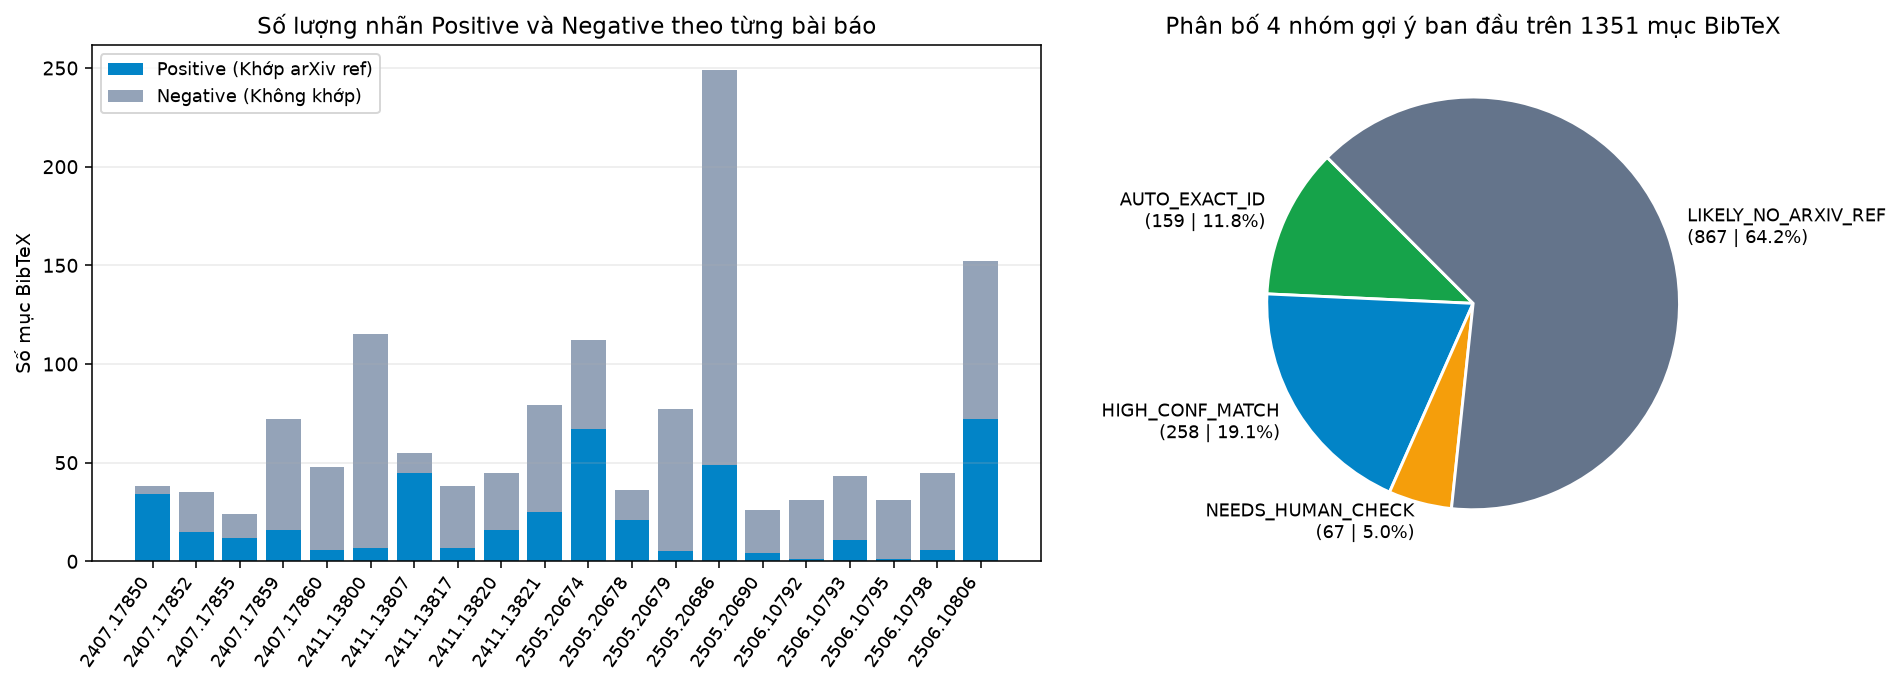

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})

pubs = per_pub_df["arxiv_id"].tolist()
pos_vals = per_pub_df["Số mục khớp (Positive)"].tolist()
neg_vals = per_pub_df["Số mục không khớp (Negative)"].tolist()

x = range(len(pubs))
axes[0].bar(x, pos_vals, label="Positive (Khớp arXiv ref)", color="#0284c7")
axes[0].bar(x, neg_vals, bottom=pos_vals, label="Negative (Không khớp)", color="#94a3b8")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(pubs, rotation=55, ha="right", fontsize=9)
axes[0].set_ylabel("Số mục BibTeX")
axes[0].set_title("Số lượng nhãn Positive và Negative theo từng bài báo")
axes[0].legend(loc="upper left", fontsize=9)
axes[0].grid(axis="y", alpha=0.25)

status_labels = [
    "AUTO_EXACT_ID\n(159 | 11.8%)",
    "HIGH_CONF_MATCH\n(258 | 19.1%)",
    "NEEDS_HUMAN_CHECK\n(67 | 5.0%)",
    "LIKELY_NO_ARXIV_REF\n(867 | 64.2%)",
]
status_sizes = [159, 258, 67, 867]
status_colors = ["#16a34a", "#0284c7", "#f59e0b", "#64748b"]
axes[1].pie(
    status_sizes,
    labels=status_labels,
    colors=status_colors,
    startangle=135,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    textprops={"fontsize": 9},
)
axes[1].set_title("Phân bố 4 nhóm gợi ý ban đầu trên 1351 mục BibTeX")

plt.tight_layout()
plt.show()
